# Experiment 8: Video Summarisation using Visual Frames and Accompanying Text

**Course:** Multimodal Data Analysis (BAI-417)
**Name:** Sneha Roychowdhury
**Section:** ECE-AI (2)

---

## Aim
To summarise video content by analysing both the visual frames and the accompanying text (subtitles), and to produce a short storyboard, a text summary and a summary video that keep the important parts of the original while removing redundant ones.

## Theory

### 1. What is video summarisation?
A video is a long sequence of frames, most of which are near-duplicates of their neighbours. Summarisation produces a compact version that keeps the key content. There are two common outputs:
- **Static summary (storyboard):** a small set of representative **keyframes**.
- **Dynamic summary (video skim):** a shorter video made of the most important **shots**.

### 2. The structure of a video
```
Video  →  Scenes  →  Shots  →  Frames
```
A **shot** is a continuous run of frames from one camera take. Shots are the natural unit for summarisation, so the first step is **shot boundary detection**.

### 3. Visual analysis
- **Colour histograms (HSV):** each frame is described by the distribution of hue, saturation and value. HSV separates colour from brightness, so it is more stable under lighting changes than RGB.
- **Shot boundary detection:** at a hard cut the histogram changes sharply. We measure the **alternative (symmetric) chi-square distance** between consecutive frames, which is what OpenCV's `HISTCMP_CHISQR_ALT` computes
  $$\chi^2_{alt}(H_1,H_2) = 2\sum_i \frac{(H_1(i) - H_2(i))^2}{H_1(i) + H_2(i)}$$
  Unlike the basic form, it treats both frames equally and does not blow up when a bin is empty in one frame.
  and mark a boundary where it exceeds an adaptive threshold $\mu + k\sigma$.
- **Keyframe selection:** the keyframe of a shot is the frame whose histogram is closest to the shot's mean histogram, so it best represents the whole shot.
- **Motion energy:** mean absolute difference between consecutive grayscale frames. Shots with activity tend to carry events.
- **Visual redundancy:** cosine similarity between keyframe histograms. Two shots that look alike (for example, a replay) should not both enter the summary.

### 4. Text analysis
Videos often come with subtitles, transcripts or captions. Subtitles in **SRT** format carry timestamps, so each line can be aligned to the shot it was spoken in. Each shot's text is turned into a **TF-IDF** vector; shots whose text contains many distinctive, informative terms receive a higher **text importance** score, while generic lines ("everyone is waiting") score low.

### 5. Multimodal fusion
Visual and textual cues are complementary: a shot may look busy but say nothing (crowd footage), or look plain but carry the key fact (an announcement). We combine them with **late fusion**:
$$S_{\text{shot}} = w_t\,S_{\text{text}} + w_m\,S_{\text{motion}} + w_v\,S_{\text{novelty}}$$
Shots are then picked greedily in order of score, skipping any shot too similar to one already chosen (a **Maximal Marginal Relevance** style rule), until a **duration budget** is reached. This is a simple greedy version of the knapsack formulation commonly used on summarisation benchmarks such as TVSum and SumMe.

## Algorithm
1. Generate the dataset: a synthetic event video (`.mp4`), its subtitles (`.srt`) and a ground-truth scene file (`.csv`).
2. Load the video and read its metadata.
3. Extract HSV histogram features and motion energy for every frame.
4. Detect shot boundaries with an adaptive threshold on histogram distance.
5. Select one keyframe per shot and build a storyboard.
6. Parse the subtitles and align each line to a shot using timestamps.
7. Score each shot on text importance (TF-IDF), motion and visual novelty.
8. Fuse the scores, select shots under a duration budget while removing redundancy.
9. Produce the storyboard summary, text summary and summary video.
10. Evaluate against ground truth and compare visual-only, text-only and multimodal summaries.

## Step 0: Import libraries
Everything used here (OpenCV, NumPy, pandas, scikit-learn, Matplotlib) is preinstalled on Colab.

In [25]:
import os, re, base64, subprocess, shutil
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import HTML, display

np.random.seed(42)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 110)
print("OpenCV version:", cv2.__version__)

OpenCV version: 4.14.0


## Step 1: Create and export the dataset
Instead of downloading a large dataset, the notebook **generates its own video** so it runs anywhere in seconds and the ground truth is known exactly.

The video shows a college **Tech Fest** in **8 scenes** (24 seconds, 10 fps, 320×240). Each scene has its own look and motion, and each comes with subtitle lines, as a real event video would.

| # | Scene | Duration | Role |
|---|---|---|---|
| S1 | Title card | 2 s | Intro |
| S2 | Audience waiting | 3 s | Filler |
| S3 | Robot race | 4 s | **Key event** |
| S4 | Audience again | 3 s | Filler (visually redundant with S2) |
| S5 | Drone light show | 4 s | **Key event** |
| S6 | Robot race replay | 3 s | Redundant with S3 |
| S7 | Prize ceremony | 3 s | **Key event** |
| S8 | Credits | 2 s | Outro |

The key events (S3, S5, S7) are stored in `scenes_ground_truth.csv` and are used only at the end for evaluation. Mild random noise is added to every frame to mimic camera sensor noise.

Files exported: `techfest.mp4`, `techfest.srt`, `scenes_ground_truth.csv`.

In [26]:
W, H, FPS = 320, 240, 10
font = cv2.FONT_HERSHEY_SIMPLEX

def gradient(c1, c2):
    """Vertical colour gradient background (BGR)."""
    a = np.linspace(0, 1, H)[:, None, None]
    return (np.array(c1) * (1 - a) + np.array(c2) * a).repeat(W, axis=1).astype(np.uint8)

def centered_text(img, text, y, scale, color, thick=2):
    (tw, _), _ = cv2.getTextSize(text, font, scale, thick)
    cv2.putText(img, text, ((W - tw) // 2, y), font, scale, color, thick, cv2.LINE_AA)

# ---- one drawing function per scene; t = frame index within the scene ----
def title_card(t):
    img = gradient((90, 30, 10), (160, 70, 20))
    centered_text(img, "TECH FEST 2026", 110, 0.9, (255, 255, 255))
    centered_text(img, "IGDTUW, Delhi", 145, 0.55, (200, 230, 255), 1)
    return img

def audience(t, seed):
    rng = np.random.default_rng(seed + t)
    img = gradient((70, 70, 75), (40, 40, 45))
    for i in range(40):                                   # heads in rows, small jitter
        x, y = 20 + (i % 10) * 31, 120 + (i // 10) * 30
        cv2.circle(img, (x + rng.integers(-2, 3), y + rng.integers(-2, 3)), 11, (120, 150, 190), -1)
    return img

def robot_race(t, replay=False):
    img = gradient((40, 120, 40), (30, 90, 30))
    for lane in range(3):
        cv2.line(img, (0, 70 + lane * 50), (W, 70 + lane * 50), (220, 220, 220), 1)
    cv2.line(img, (290, 50), (290, 200), (255, 255, 255), 3)          # finish line
    speeds = [7, 6, 5]
    for lane, (sp, col) in enumerate(zip(speeds, [(0, 0, 230), (230, 120, 0), (0, 200, 230)])):
        x = 10 + (t * sp) % 270 if not replay else 150 + (t * sp) % 130
        cv2.rectangle(img, (int(x), 80 + lane * 50), (int(x) + 26, 106 + lane * 50), col, -1)
    if replay:
        cv2.putText(img, "REPLAY", (10, 30), font, 0.7, (255, 255, 255), 2, cv2.LINE_AA)
    return img

def drone_show(t):
    img = gradient((60, 10, 40), (20, 0, 10))
    for k in range(16):                                   # drones rotating in a ring
        ang = 2 * np.pi * k / 16 + t * 0.12
        x, y = int(160 + 85 * np.cos(ang)), int(120 + 70 * np.sin(ang))
        cv2.circle(img, (x, y), 5, (255, 220, 120), -1)
    cv2.circle(img, (160, 120), 10 + (t % 10), (255, 255, 255), 2)
    return img

def prize_ceremony(t):
    img = gradient((30, 160, 210), (20, 110, 170))
    cv2.rectangle(img, (130, 170), (190, 200), (40, 40, 40), -1)            # trophy base
    cv2.rectangle(img, (150, 120), (170, 170), (0, 200, 255), -1)          # stem
    cv2.ellipse(img, (160, 105), (40, 30), 0, 0, 180, (0, 215, 255), -1)   # cup
    for k in range(12):                                                    # falling confetti
        x, y = (k * 29 + 7) % W, (t * 6 + k * 23) % H
        cv2.rectangle(img, (x, y), (x + 5, y + 5), (255, 255, 255), -1)
    return img

def credits(t):
    img = np.zeros((H, W, 3), np.uint8)
    for i, line in enumerate(["Organised by", "IGDTUW Tech Council", "Thank you"]):
        centered_text(img, line, 190 - t * 6 + i * 35, 0.6, (200, 200, 200), 1)
    return img

scenes = [
    ("S1", "Title card",        2, title_card),
    ("S2", "Audience waiting",  3, lambda t: audience(t, 0)),
    ("S3", "Robot race",        4, robot_race),
    ("S4", "Audience again",    3, lambda t: audience(t, 999)),
    ("S5", "Drone light show",  4, drone_show),
    ("S6", "Robot race replay", 3, lambda t: robot_race(t, replay=True)),
    ("S7", "Prize ceremony",    3, prize_ceremony),
    ("S8", "Credits",           2, credits),
]

# ---- write the video ----
writer = cv2.VideoWriter("techfest.mp4", cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
gt_rows, start = [], 0
for sid, name, dur, fn in scenes:
    n = dur * FPS
    for t in range(n):
        frame = fn(t).astype(np.int16) + np.random.normal(0, 4, (H, W, 3)).astype(np.int16)
        writer.write(np.clip(frame, 0, 255).astype(np.uint8))
    gt_rows.append({"scene_id": sid, "name": name, "start_frame": start, "end_frame": start + n - 1,
                    "start_s": start / FPS, "end_s": (start + n) / FPS,
                    "is_key": sid in ("S3", "S5", "S7")})
    start += n
writer.release()
pd.DataFrame(gt_rows).to_csv("scenes_ground_truth.csv", index=False)

# ---- write the subtitles (SRT) ----
subtitles = [
    (0.0, 2.0,  "Welcome to Tech Fest 2026 at IGDTUW Delhi."),
    (2.0, 3.5,  "The audience is settling in."),
    (3.5, 5.0,  "Everyone is waiting for the show to begin."),
    (5.0, 7.0,  "The robot race begins with three autonomous bots built by second year students."),
    (7.0, 9.0,  "The red line-following robot takes the lead using a PID controller and infrared sensors."),
    (9.0, 10.5, "The crowd is cheering."),
    (10.5, 12.0, "Everyone is enjoying the event."),
    (12.0, 14.0, "Next, sixteen drones perform a synchronised light show programmed with swarm algorithms."),
    (14.0, 16.0, "The drones form a rotating ring controlled over a single wireless ground station."),
    (16.0, 17.5, "Here is the replay of the race finish from the trackside camera."),
    (17.5, 19.0, "The red line-following robot overtakes on the final curve and crosses the finish line two seconds ahead, a new fest record."),
    (19.0, 20.5, "Team Circuit Queens wins the first prize of fifty thousand rupees for the robot race."),
    (20.5, 22.0, "The drone team receives a special award for innovation from the Vice Chancellor."),
    (22.0, 24.0, "Thank you for watching."),
]
def ts(sec):
    ms = int(round(sec * 1000)); h, ms = divmod(ms, 3600000); m, ms = divmod(ms, 60000); s, ms = divmod(ms, 1000)
    return f"{h:02d}:{m:02d}:{s:02d},{ms:03d}"
with open("techfest.srt", "w", encoding="utf-8") as f:
    for i, (a, b, txt) in enumerate(subtitles, 1):
        f.write(f"{i}\n{ts(a)} --> {ts(b)}\n{txt}\n\n")

for fn in ["techfest.mp4", "techfest.srt", "scenes_ground_truth.csv"]:
    print(f"Exported {fn:<26} {os.path.getsize(fn)/1024:7.1f} KB")

Exported techfest.mp4                 652.3 KB
Exported techfest.srt                   1.3 KB
Exported scenes_ground_truth.csv        0.4 KB


A peek at the exported subtitle file:

In [27]:
print(open("techfest.srt").read()[:420], "...")

1
00:00:00,000 --> 00:00:02,000
Welcome to Tech Fest 2026 at IGDTUW Delhi.

2
00:00:02,000 --> 00:00:03,500
The audience is settling in.

3
00:00:03,500 --> 00:00:05,000
Everyone is waiting for the show to begin.

4
00:00:05,000 --> 00:00:07,000
The robot race begins with three autonomous bots built by second year students.

5
00:00:07,000 --> 00:00:09,000
The red line-following robot takes the lead using a PID contr ...


### Helper to play videos inside the notebook
OpenCV writes `mp4v`, which browsers do not play. If `ffmpeg` is available (it is on Colab) the helper re-encodes to H.264 and embeds the video. The analysis itself does not depend on this.

In [28]:
def show_video(path, width=400):
    if shutil.which("ffmpeg") is None:
        print("ffmpeg not found, skipping playback. The file is saved as", path)
        return
    out = path.replace(".mp4", "_h264.mp4")
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", path, "-vcodec", "libx264",
                    "-pix_fmt", "yuv420p", out], check=True)
    b64 = base64.b64encode(open(out, "rb").read()).decode()
    display(HTML(f'<video width="{width}" controls><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>'))

show_video("techfest.mp4")

## Step 2: Load the video and read its metadata

In [29]:
cap = cv2.VideoCapture("techfest.mp4")
fps = cap.get(cv2.CAP_PROP_FPS)
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
frames = []
while True:
    ok, fr = cap.read()
    if not ok:
        break
    frames.append(fr)
cap.release()
frames = np.array(frames)
duration = len(frames) / fps

print(f"Resolution : {frames.shape[2]} x {frames.shape[1]}")
print(f"FPS        : {fps:.0f}")
print(f"Frames     : {len(frames)}")
print(f"Duration   : {duration:.1f} s")
print(f"Array shape: {frames.shape}  (frames, height, width, channels)")

Resolution : 320 x 240
FPS        : 10
Frames     : 240
Duration   : 24.0 s
Array shape: (240, 240, 320, 3)  (frames, height, width, channels)


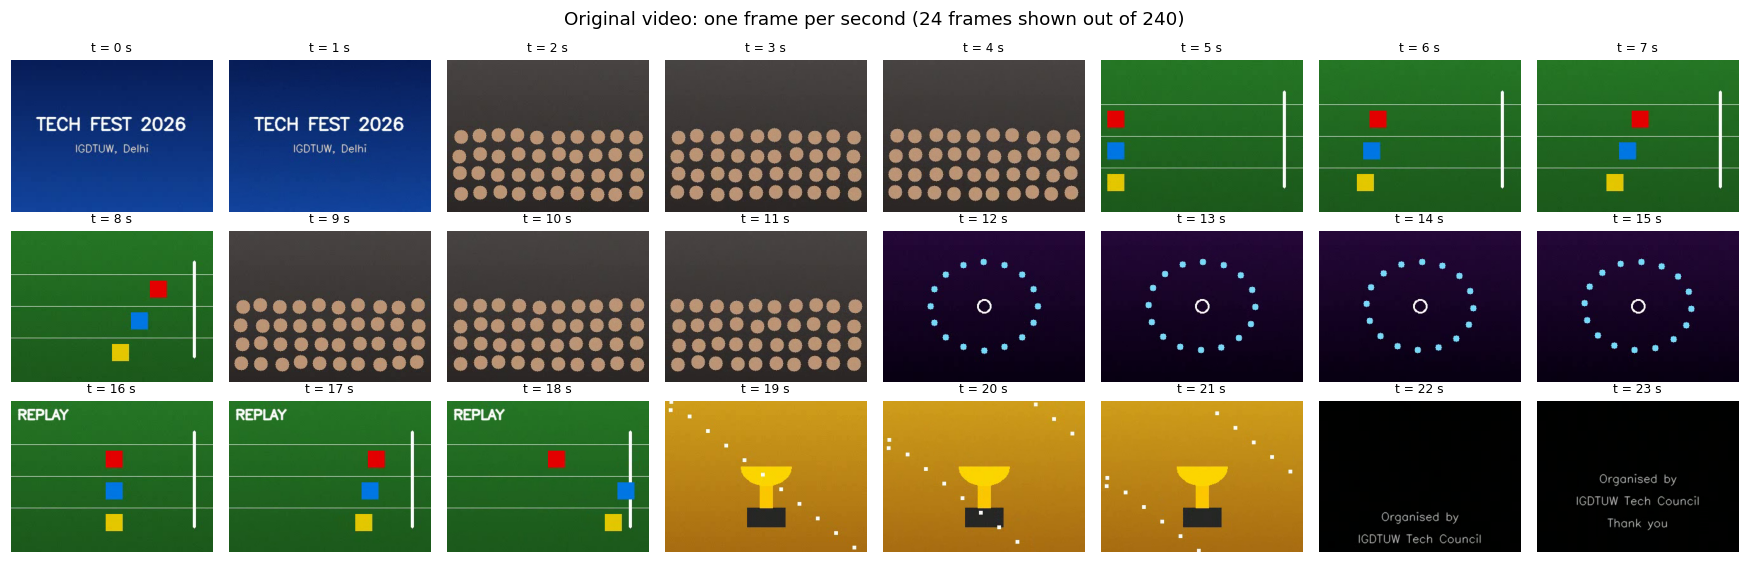

In [30]:
# One frame every second gives a quick overview of the full video
fig, axes = plt.subplots(3, 8, figsize=(16, 5.2))
for ax, i in zip(axes.ravel(), range(0, len(frames), int(fps))):
    ax.imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB))
    ax.set_title(f"t = {i/fps:.0f} s", fontsize=8)
    ax.axis("off")
plt.suptitle("Original video: one frame per second (24 frames shown out of 240)")
plt.tight_layout()
plt.show()

## Step 3: Visual feature extraction
For every frame we compute:
1. A **256-dimensional HSV histogram** (16 hue × 4 saturation × 4 value bins), normalised to sum to 1.
2. **Motion energy**: mean absolute difference from the previous grayscale frame (blurred first, so sensor noise is not counted as motion).

In [31]:
def hsv_hist(frame, bins=(16, 4, 4)):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    h = cv2.calcHist([hsv], [0, 1, 2], None, bins, [0, 180, 0, 256, 0, 256]).ravel()
    return h / h.sum()

hists = np.array([hsv_hist(f) for f in frames])
gray = np.array([cv2.GaussianBlur(cv2.cvtColor(f, cv2.COLOR_BGR2GRAY), (5, 5), 0) for f in frames]).astype(np.float32)
motion = np.r_[0, np.abs(np.diff(gray, axis=0)).mean(axis=(1, 2))]

print("Histogram feature matrix:", hists.shape)
print("Motion vector           :", motion.shape)

Histogram feature matrix: (240, 256)
Motion vector           : (240,)


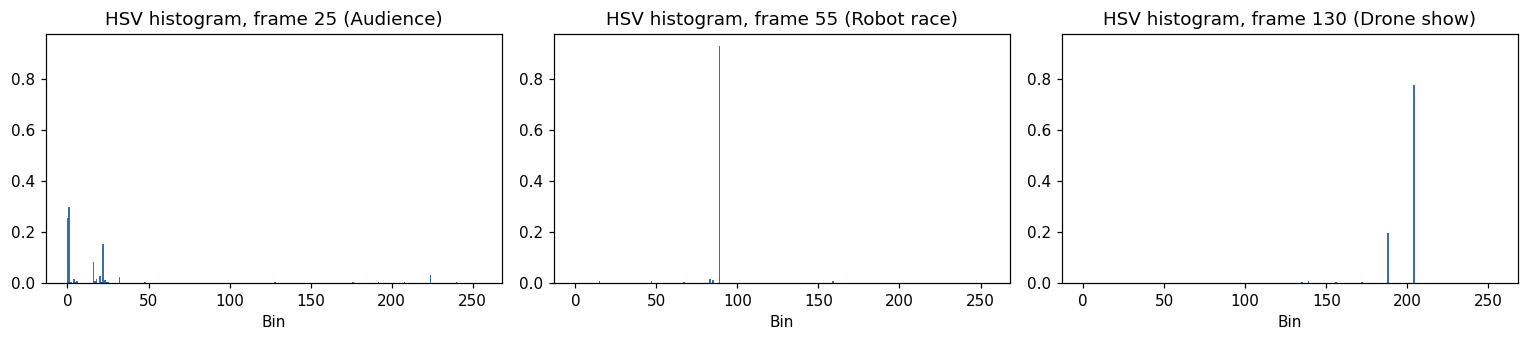

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, (idx, lab) in zip(axes, [(25, "Audience"), (55, "Robot race"), (130, "Drone show")]):
    ax.bar(range(256), hists[idx], color="#3b6ea5", width=1.0)
    ax.set_title(f"HSV histogram, frame {idx} ({lab})")
    ax.set_xlabel("Bin"); ax.set_ylim(0, hists[[25, 55, 130]].max() * 1.05)
plt.tight_layout()
plt.show()

## Step 4: Shot boundary detection
The chi-square distance between consecutive histograms stays near zero inside a shot and spikes at a cut. The threshold adapts to the video: $T = \mu + 3\sigma$ of all distances.

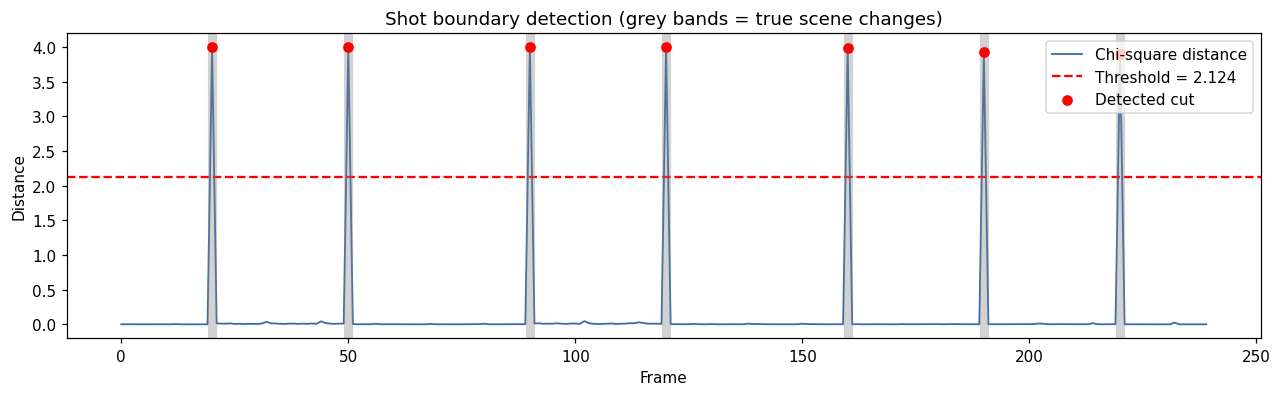

Detected boundaries at frames: [20, 50, 90, 120, 160, 190, 220]
True boundaries at frames    : [20, 50, 90, 120, 160, 190, 220]
Boundary recall: 7/7 | False alarms: 0


In [33]:
dist = np.r_[0, [cv2.compareHist(hists[i - 1].astype(np.float32), hists[i].astype(np.float32),
                                 cv2.HISTCMP_CHISQR_ALT) for i in range(1, len(hists))]]
T = dist.mean() + 3 * dist.std()
boundaries = [0] + [i for i in range(1, len(dist)) if dist[i] > T]

gt = pd.read_csv("scenes_ground_truth.csv")
true_bounds = gt.start_frame.tolist()

plt.figure(figsize=(14, 3.6))
plt.plot(dist, color="#3b6ea5", lw=1.2, label="Chi-square distance")
plt.axhline(T, color="red", ls="--", label=f"Threshold = {T:.3f}")
for b in true_bounds[1:]:
    plt.axvline(b, color="grey", alpha=0.35, lw=6)
plt.scatter(boundaries[1:], dist[boundaries[1:]], color="red", zorder=5, label="Detected cut")
plt.xlabel("Frame"); plt.ylabel("Distance")
plt.title("Shot boundary detection (grey bands = true scene changes)")
plt.legend(loc="upper right")
plt.show()

hits = sum(any(abs(b - t) <= 1 for b in boundaries[1:]) for t in true_bounds[1:])
print("Detected boundaries at frames:", boundaries[1:])
print("True boundaries at frames    :", true_bounds[1:])
print(f"Boundary recall: {hits}/{len(true_bounds)-1} | False alarms: {len(boundaries)-1-hits}")

In [34]:
shot_edges = boundaries + [len(frames)]
shots = pd.DataFrame({"shot": [f"Shot {i+1}" for i in range(len(shot_edges) - 1)],
                      "start": shot_edges[:-1], "end": [e - 1 for e in shot_edges[1:]]})
shots["start_s"] = shots.start / fps
shots["end_s"] = (shots.end + 1) / fps
shots["duration_s"] = shots.end_s - shots.start_s
shots

,shot,start,end,start_s,end_s,duration_s
0,Shot 1,0,19,0.0,2.0,2.0
1,Shot 2,20,49,2.0,5.0,3.0
2,Shot 3,50,89,5.0,9.0,4.0
3,Shot 4,90,119,9.0,12.0,3.0
4,Shot 5,120,159,12.0,16.0,4.0
5,Shot 6,160,189,16.0,19.0,3.0
6,Shot 7,190,219,19.0,22.0,3.0
7,Shot 8,220,239,22.0,24.0,2.0


## Step 5: Keyframe extraction and storyboard
For each shot the keyframe is the frame closest (Euclidean distance) to the shot's mean histogram, meaning it is the most typical frame of that shot rather than a random or first frame.

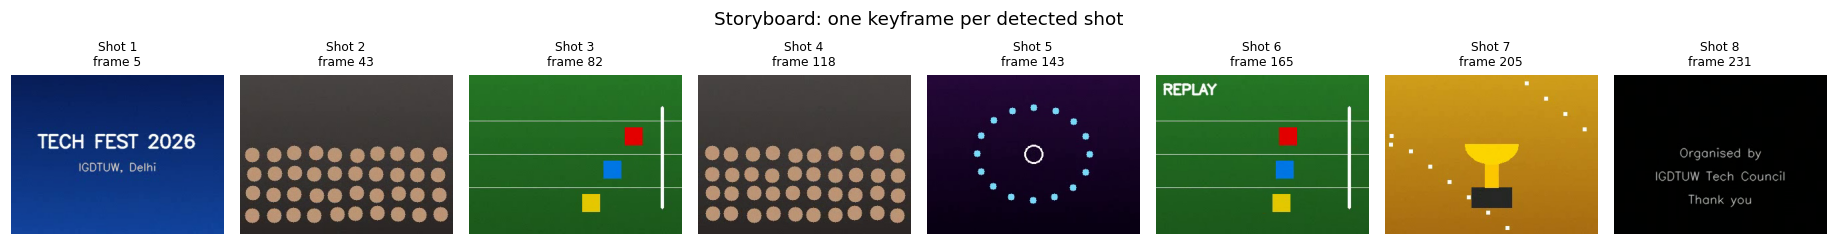

In [35]:
keyframes = []
for _, s in shots.iterrows():
    seg = hists[s.start:s.end + 1]
    centre = seg.mean(axis=0)
    keyframes.append(int(s.start + np.argmin(np.linalg.norm(seg - centre, axis=1))))
shots["keyframe"] = keyframes
shots["motion"] = [motion[s.start + 1:s.end + 1].mean() for _, s in shots.iterrows()]

fig, axes = plt.subplots(1, len(shots), figsize=(2.1 * len(shots), 2.4))
for ax, (_, s) in zip(axes, shots.iterrows()):
    ax.imshow(cv2.cvtColor(frames[s.keyframe], cv2.COLOR_BGR2RGB))
    ax.set_title(f"{s.shot}\nframe {s.keyframe}", fontsize=8)
    ax.axis("off")
plt.suptitle("Storyboard: one keyframe per detected shot")
plt.tight_layout()
plt.show()

### 5.1 Visual redundancy between shots
Cosine similarity of keyframe histograms. Bright off-diagonal cells mean two different shots look alike, which is exactly what a summary should avoid repeating.

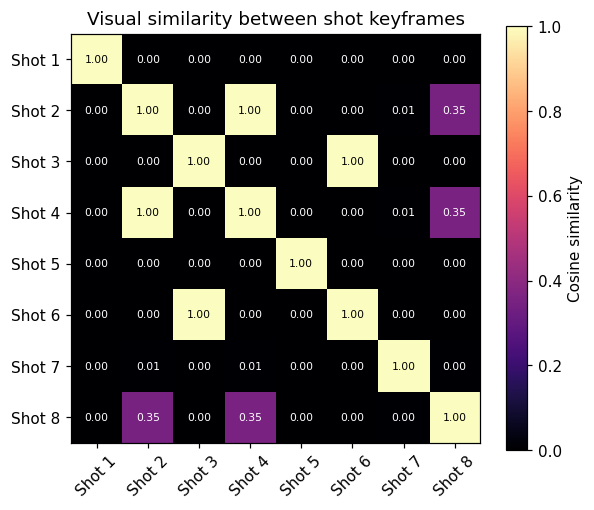

In [36]:
kf_feats = hists[shots.keyframe.values]
vis_sim = cosine_similarity(kf_feats)

plt.figure(figsize=(6, 5))
plt.imshow(vis_sim, cmap="magma", vmin=0, vmax=1)
plt.colorbar(label="Cosine similarity")
plt.xticks(range(len(shots)), shots.shot, rotation=45); plt.yticks(range(len(shots)), shots.shot)
for i in range(len(shots)):
    for j in range(len(shots)):
        plt.text(j, i, f"{vis_sim[i, j]:.2f}", ha="center", va="center", fontsize=7,
                 color="black" if vis_sim[i, j] > 0.6 else "white")
plt.title("Visual similarity between shot keyframes")
plt.show()

## Step 6: Text analysis of the subtitles
### 6.1 Parse the SRT file and align lines to shots
Each subtitle line is assigned to the shot that contains its midpoint time.

In [37]:
def parse_srt(path):
    blocks = open(path, encoding="utf-8").read().strip().split("\n\n")
    to_s = lambda x: sum(float(v) * m for v, m in zip(x.replace(",", ".").split(":"), [3600, 60, 1]))
    rows = []
    for b in blocks:
        lines = b.splitlines()
        a, z = [to_s(p.strip()) for p in lines[1].split("-->")]
        rows.append({"start_s": a, "end_s": z, "text": " ".join(lines[2:])})
    return pd.DataFrame(rows)

subs = parse_srt("techfest.srt")
subs["mid_s"] = (subs.start_s + subs.end_s) / 2
subs["shot"] = [shots.shot[(shots.start_s <= m) & (m < shots.end_s)].iloc[0] for m in subs.mid_s]
subs

,start_s,end_s,text,mid_s,shot
0,0.0,2.0,Welcome to Tech Fest 2026 at IGDTUW Delhi.,1.00,Shot 1
1,2.0,3.5,The audience is settling in.,2.75,Shot 2
2,3.5,5.0,Everyone is waiting for the show to begin.,4.25,Shot 2
3,5.0,7.0,The robot race begins with three autonomous bots built by second year students.,6.00,Shot 3
4,7.0,9.0,The red line-following robot takes the lead using a PID controller and infrared sensors.,8.00,Shot 3
5,9.0,10.5,The crowd is cheering.,9.75,Shot 4
6,10.5,12.0,Everyone is enjoying the event.,11.25,Shot 4
7,12.0,14.0,"Next, sixteen drones perform a synchronised light show programmed with swarm algorithms.",13.00,Shot 5
8,14.0,16.0,The drones form a rotating ring controlled over a single wireless ground station.,15.00,Shot 5
9,16.0,17.5,Here is the replay of the race finish from the trackside camera.,16.75,Shot 6


In [38]:
shot_text = subs.groupby("shot", sort=False)["text"].apply(" ".join)
shots["text"] = shots.shot.map(shot_text).fillna("")
shots[["shot", "start_s", "end_s", "text"]]

,shot,start_s,end_s,text
0,Shot 1,0.0,2.0,Welcome to Tech Fest 2026 at IGDTUW Delhi.
1,Shot 2,2.0,5.0,The audience is settling in. Everyone is waiting for the show to begin.
2,Shot 3,5.0,9.0,The robot race begins with three autonomous bots built by second year students. The red line-following rob...
3,Shot 4,9.0,12.0,The crowd is cheering. Everyone is enjoying the event.
4,Shot 5,12.0,16.0,"Next, sixteen drones perform a synchronised light show programmed with swarm algorithms. The drones form a..."
5,Shot 6,16.0,19.0,Here is the replay of the race finish from the trackside camera. The red line-following robot overtakes on...
6,Shot 7,19.0,22.0,Team Circuit Queens wins the first prize of fifty thousand rupees for the robot race. The drone team recei...
7,Shot 8,22.0,24.0,Thank you for watching.


### 6.2 Text importance with TF-IDF
Each shot's text is one "document". Stopwords are removed, and the importance of a shot is the **sum of TF-IDF weights of its terms** (with sublinear TF). Shots with many specific terms (*autonomous, PID controller, swarm algorithms, first prize*) score high; generic lines score low.

In [39]:
vec = TfidfVectorizer(stop_words="english", sublinear_tf=True, norm=None)
X_text = vec.fit_transform(shots.text)
terms = vec.get_feature_names_out()

shots["text_raw"] = np.asarray(X_text.sum(axis=1)).ravel()
shots["top_terms"] = [", ".join(terms[X_text[i].toarray().ravel().argsort()[::-1][:4]])
                      for i in range(len(shots))]
shots[["shot", "text_raw", "top_terms"]].round(2)

,shot,text_raw,top_terms
0,Shot 1,14.62,"welcome, tech, igdtuw, 2026"
1,Shot 2,10.02,"waiting, begin, audience, settling"
2,Shot 3,46.23,"robot, using, controller, bots"
3,Shot 4,10.02,"cheering, enjoying, crowd, event"
4,Shot 5,41.80,"drones, algorithms, form, light"
5,Shot 6,45.26,"finish, line, camera, ahead"
6,Shot 7,40.41,"team, vice, thousand, wins"
7,Shot 8,5.01,"watching, thank, year, wins"


## Step 7: Score each shot on three cues
| Cue | Source | Idea |
|---|---|---|
| **Text importance** $S_{text}$ | TF-IDF of subtitles | Says something informative |
| **Motion** $S_{motion}$ | Frame differences | Something is happening |
| **Visual novelty** $S_{novelty}$ | Keyframe similarity | Looks unlike the shots before it |

Visual novelty is computed as $1 - \max_{j<i} \text{sim}(i, j)$, so a shot that repeats an earlier look gets a low score. All three are min-max normalised to $[0, 1]$.

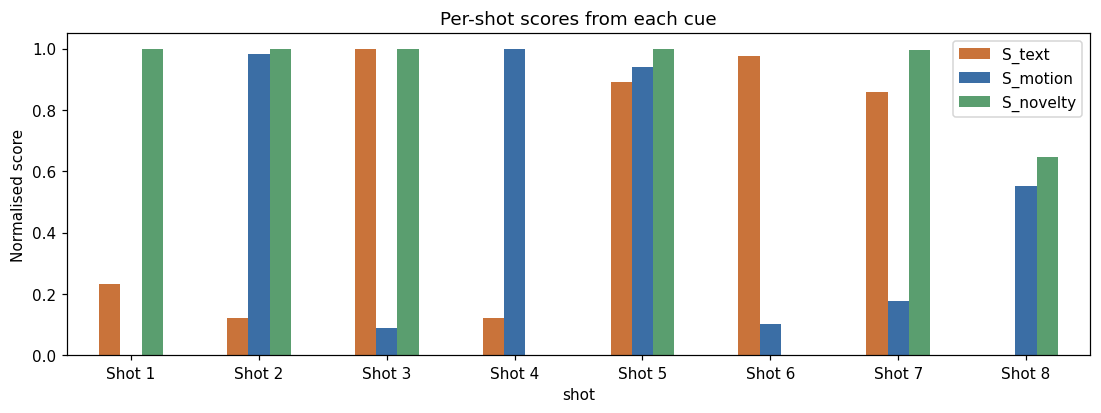

,shot,duration_s,S_text,S_motion,S_novelty
0,Shot 1,2.0,0.233,0.000,1.000
1,Shot 2,3.0,0.121,0.983,1.000
2,Shot 3,4.0,1.000,0.088,1.000
3,Shot 4,3.0,0.121,1.000,0.000
4,Shot 5,4.0,0.893,0.941,1.000
5,Shot 6,3.0,0.976,0.100,0.000
6,Shot 7,3.0,0.859,0.177,0.995
7,Shot 8,2.0,0.000,0.552,0.648


In [40]:
norm = lambda v: (v - v.min()) / (v.max() - v.min() + 1e-12)

novelty = np.array([1.0] + [1 - vis_sim[i, :i].max() for i in range(1, len(shots))])
shots["S_text"] = norm(shots.text_raw.values)
shots["S_motion"] = norm(shots.motion.values)
shots["S_novelty"] = norm(novelty)

ax = shots.set_index("shot")[["S_text", "S_motion", "S_novelty"]].plot(
        kind="bar", figsize=(12, 3.8), color=["#c9733a", "#3b6ea5", "#5a9e6f"], rot=0)
ax.set_title("Per-shot scores from each cue"); ax.set_ylabel("Normalised score")
plt.show()
shots[["shot", "duration_s", "S_text", "S_motion", "S_novelty"]].round(3)

## Step 8: Multimodal fusion and shot selection
1. Fused score: $S = 0.5\,S_{text} + 0.25\,S_{motion} + 0.25\,S_{novelty}$. Text gets the largest weight because in event videos the commentary names what actually matters.
2. Sort shots by $S$ and add them one by one while:
   - the total duration stays within the **budget (50% of the original)**, and
   - the shot's visual similarity to every already selected shot stays below **0.9** (redundancy filter).
3. Put the selected shots back in **chronological order** so the summary tells the story in sequence.

In [41]:
BUDGET = 0.5 * duration
SIM_MAX = 0.9

def summarise(scores, budget=BUDGET, sim_max=SIM_MAX, redundancy_filter=True):
    chosen, used = [], 0.0
    for i in np.argsort(scores)[::-1]:
        d = shots.duration_s[i]
        if used + d > budget:
            continue
        if redundancy_filter and any(vis_sim[i, j] > sim_max for j in chosen):
            continue
        chosen.append(i); used += d
    return sorted(chosen)

shots["S_fused"] = 0.5 * shots.S_text + 0.25 * shots.S_motion + 0.25 * shots.S_novelty
selected = summarise(shots.S_fused.values)
shots["selected"] = shots.index.isin(selected)

print(f"Budget: {BUDGET:.1f} s of {duration:.1f} s")
shots[["shot", "duration_s", "S_text", "S_motion", "S_novelty", "S_fused", "selected"]].round(3)

Budget: 12.0 s of 24.0 s


,shot,duration_s,S_text,S_motion,S_novelty,S_fused,selected
0,Shot 1,2.0,0.233,0.000,1.000,0.367,False
1,Shot 2,3.0,0.121,0.983,1.000,0.557,False
2,Shot 3,4.0,1.000,0.088,1.000,0.772,True
3,Shot 4,3.0,0.121,1.000,0.000,0.311,False
4,Shot 5,4.0,0.893,0.941,1.000,0.931,True
5,Shot 6,3.0,0.976,0.100,0.000,0.513,False
6,Shot 7,3.0,0.859,0.177,0.995,0.722,True
7,Shot 8,2.0,0.000,0.552,0.648,0.300,False


## Step 9: The summary
### 9.1 Storyboard summary with captions

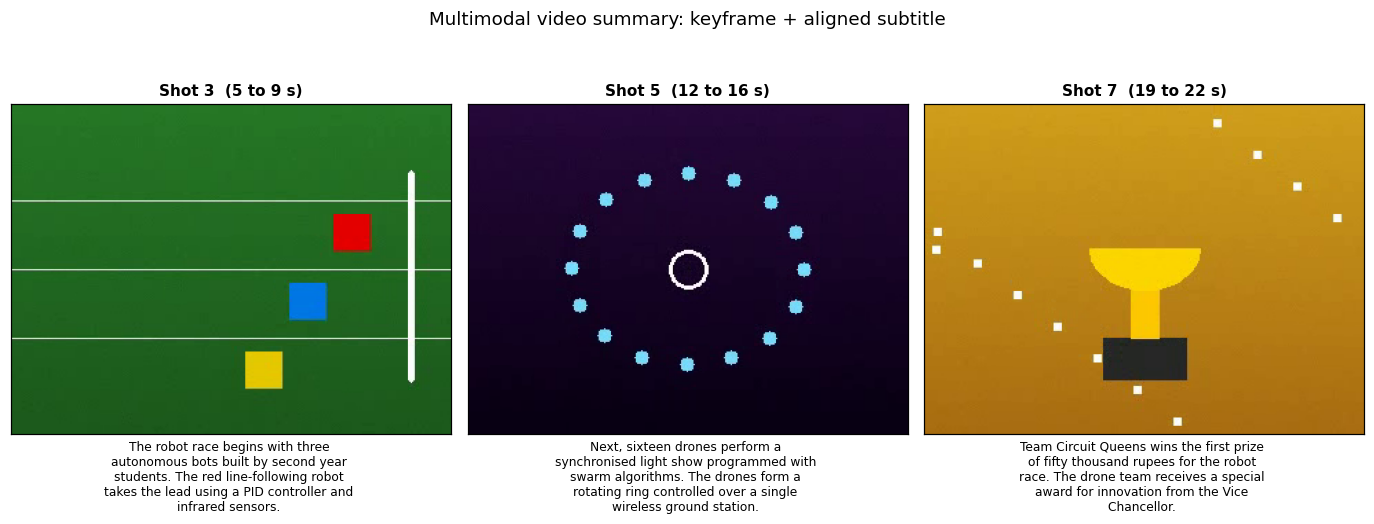

In [42]:
sel = shots.loc[selected]
fig, axes = plt.subplots(1, len(sel), figsize=(4.2 * len(sel), 4.6))
axes = np.atleast_1d(axes)
for ax, (_, s) in zip(axes, sel.iterrows()):
    ax.imshow(cv2.cvtColor(frames[s.keyframe], cv2.COLOR_BGR2RGB))
    words, line, wrapped = s.text.split(), "", []
    for w_ in words:
        if len(line) + len(w_) > 42:
            wrapped.append(line); line = ""
        line += w_ + " "
    wrapped.append(line)
    ax.set_title(f"{s.shot}  ({s.start_s:.0f} to {s.end_s:.0f} s)", fontsize=10, fontweight="bold")
    ax.set_xlabel("\n".join(wrapped), fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Multimodal video summary: keyframe + aligned subtitle", fontsize=12)
plt.tight_layout()
plt.show()

### 9.2 Text summary
The subtitles of the selected shots, in order, form a readable paragraph summary of the event.

In [43]:
text_summary = " ".join(sel.text)
print("TEXT SUMMARY")
print("=" * 70)
print(text_summary)
print("=" * 70)
print(f"Words: {len(' '.join(shots.text).split())} in full transcript -> {len(text_summary.split())} in summary")

TEXT SUMMARY
The robot race begins with three autonomous bots built by second year students. The red line-following robot takes the lead using a PID controller and infrared sensors. Next, sixteen drones perform a synchronised light show programmed with swarm algorithms. The drones form a rotating ring controlled over a single wireless ground station. Team Circuit Queens wins the first prize of fifty thousand rupees for the robot race. The drone team receives a special award for innovation from the Vice Chancellor.
Words: 147 in full transcript -> 80 in summary


### 9.3 Summary video (video skim)
Frames from the selected shots are written into `techfest_summary.mp4`.

In [44]:
writer = cv2.VideoWriter("techfest_summary.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
n_written = 0
for _, s in sel.iterrows():
    for f in frames[s.start:s.end + 1]:
        writer.write(f); n_written += 1
writer.release()

summary_dur = n_written / fps
print(f"Original : {len(frames)} frames, {duration:.1f} s")
print(f"Summary  : {n_written} frames, {summary_dur:.1f} s")
print(f"Compression ratio: {summary_dur / duration:.0%} of original length "
      f"({1 - summary_dur / duration:.0%} reduction)")
show_video("techfest_summary.mp4")

Original : 240 frames, 24.0 s
Summary  : 110 frames, 11.0 s
Compression ratio: 46% of original length (54% reduction)


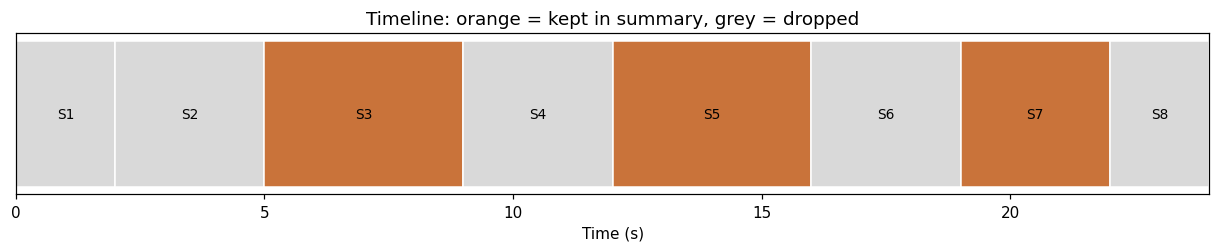

In [45]:
# Timeline view: which parts of the original video survived
plt.figure(figsize=(14, 1.9))
for _, s in shots.iterrows():
    plt.barh(0, s.duration_s, left=s.start_s, color="#c9733a" if s.selected else "#d9d9d9", edgecolor="white")
    plt.text(s.start_s + s.duration_s / 2, 0, s.shot.replace("Shot ", "S"), ha="center", va="center", fontsize=9)
plt.yticks([]); plt.xlabel("Time (s)")
plt.title("Timeline: orange = kept in summary, grey = dropped")
plt.xlim(0, duration)
plt.show()

## Step 10: Evaluation and ablation study
The selected shots are compared with the ground-truth key scenes in `scenes_ground_truth.csv`. To see what each modality contributes, the same selection procedure is run with:
- **Visual only:** $0.5\,S_{motion} + 0.5\,S_{novelty}$, with the visual redundancy filter
- **Text only:** $S_{text}$, without the redundancy filter (that filter uses visual information)
- **Multimodal (fused):** the combined score above

Metrics: **Precision** (selected shots that are key), **Recall** (key shots that were selected) and **F1**.

In [46]:
# map each detected shot to the ground-truth scene it overlaps most
def gt_scene(s):
    ov = [(min(s.end, g.end_frame) - max(s.start, g.start_frame), g.scene_id) for _, g in gt.iterrows()]
    return max(ov)[1]
shots["gt_scene"] = shots.apply(gt_scene, axis=1)
key_ids = set(gt.scene_id[gt.is_key])

def evaluate(chosen):
    picked = set(shots.gt_scene[chosen])
    tp = len(picked & key_ids)
    p, r = tp / max(len(picked), 1), tp / len(key_ids)
    f1 = 2 * p * r / (p + r + 1e-12)
    return p, r, f1, ", ".join(sorted(picked))

# (score, use visual redundancy filter?). Text only must not peek at visual similarity.
variants = {
    "Visual only": (0.5 * shots.S_motion + 0.5 * shots.S_novelty, True),
    "Text only": (shots.S_text, False),
    "Multimodal (fused)": (shots.S_fused, True),
}
res = []
for name, (sc, filt) in variants.items():
    p, r, f1, picked = evaluate(summarise(sc.values, redundancy_filter=filt))
    res.append({"Method": name, "Scenes selected": picked, "Precision": p, "Recall": r, "F1": f1})
results = pd.DataFrame(res).set_index("Method").round(3)
print("Ground-truth key scenes:", ", ".join(sorted(key_ids)))
results

Ground-truth key scenes: S3, S5, S7


,Scenes selected,Precision,Recall,F1
Method,,,,
Visual only,"S2, S5, S7, S8",0.500,0.667,0.571
Text only,"S3, S5, S6",0.667,0.667,0.667
Multimodal (fused),"S3, S5, S7",1.000,1.000,1.000


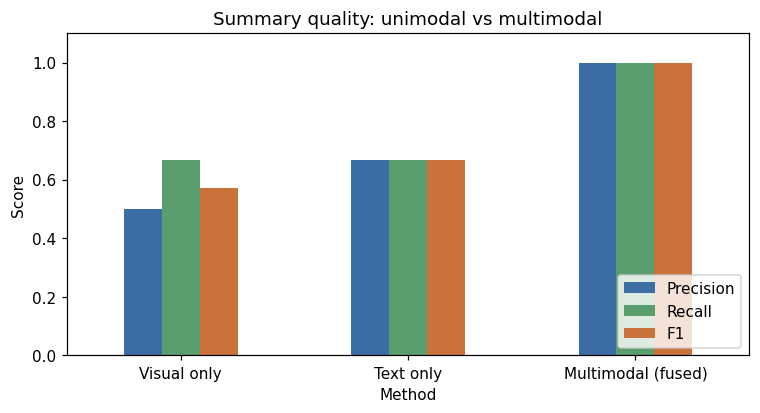

In [47]:
results[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(8, 3.8), rot=0,
                                            color=["#3b6ea5", "#5a9e6f", "#c9733a"])
plt.ylim(0, 1.1); plt.ylabel("Score")
plt.title("Summary quality: unimodal vs multimodal")
plt.legend(loc="lower right")
plt.show()

### 10.1 Effect of the fusion weight
The text weight $w_t$ is varied from 0 to 1, with the remaining weight split equally between motion and novelty.

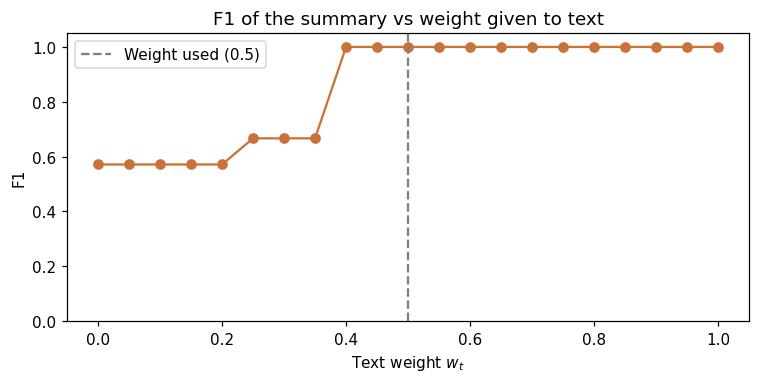

In [48]:
ws = np.linspace(0, 1, 21)
f1s = [evaluate(summarise((w * shots.S_text + (1 - w) / 2 * (shots.S_motion + shots.S_novelty)).values))[2] for w in ws]
plt.figure(figsize=(8, 3.4))
plt.plot(ws, f1s, "o-", color="#c9733a")
plt.axvline(0.5, color="grey", ls="--", label="Weight used (0.5)")
plt.xlabel("Text weight $w_t$"); plt.ylabel("F1"); plt.ylim(0, 1.05)
plt.title("F1 of the summary vs weight given to text")
plt.legend()
plt.show()

## Results and Observations
1. **Shot boundary detection** found all 7 cuts with no false alarms. Inside a shot the chi-square distance stays near zero even with sensor noise, and every cut produces a clear spike, so the adaptive threshold $\mu + 3\sigma$ works without manual tuning.
2. **Keyframes** give a clean storyboard of 8 shots, and the similarity heatmap correctly shows two redundant pairs with similarity of about 1.0: the two audience shots (Shot 2 and Shot 4) and the race with its replay (Shot 3 and Shot 6).
3. **Motion alone is misleading.** The audience shots have the highest motion score because every head jitters slightly, while the robot race scores low because only three small robots move. Pixel activity is not the same as an important event.
4. **Text gives the strongest single signal.** Informative commentary (robot race, drone show, prize ceremony) scores far above generic lines like "the crowd is cheering" or "thank you for watching".
5. **Ablation results:**
   - *Visual only* picked the audience, drone show, prize ceremony and credits (F1 = 0.57). It missed the robot race and included two filler shots.
   - *Text only* picked the race, drone show and the **replay** (F1 = 0.67). The replay commentary is detailed, so on text it looks important, but the viewer has already seen that footage. It then ran out of budget and dropped the prize ceremony.
   - *Multimodal* picked exactly the three key scenes (F1 = 1.0). The replay has strong text but zero visual novelty (it repeats Shot 3) and little motion, so its fused score (0.51) fell below the prize ceremony (0.72), and the budget was filled before the replay's turn came.
6. **Weight sensitivity:** F1 is 1.0 for every text weight from 0.4 to 1.0 and falls once visual cues dominate ($w_t < 0.4$). Note that this sweep keeps the visual redundancy filter on. That is why $w_t = 1.0$ still reaches F1 = 1.0 here, while the text-only run above (no filter) reaches only 0.67: at $w_t = 1.0$ the filter blocks the replay because it is visually identical to Shot 3. So text should carry the main weight, with visual analysis checking for redundancy.
7. The final summary is **11 s out of 24 s (46%)** and the text summary uses 80 of 147 words, while still covering every key event in order.
8. **Limitations:** the text score is a plain sum of TF-IDF weights, so shots with more spoken words get a natural advantage. Dividing by length, or using sentence embeddings, would reduce this bias. Also, this is a controlled synthetic video. Real footage has gradual transitions (fades, dissolves), camera motion and noisy speech-to-text transcripts. Deep features (for example CNN or CLIP embeddings for frames, and sentence embeddings for text) would handle these better than colour histograms and TF-IDF.

## Conclusion
A multimodal video summarisation pipeline was built that analyses visual frames (HSV histograms, motion, keyframe similarity) together with the accompanying subtitles (TF-IDF importance, timestamp alignment). Shot boundaries were detected with an adaptive histogram-distance threshold, each shot was represented by a keyframe, and shots were selected by a fused score under a duration budget with a redundancy filter. The result is a storyboard, a text summary and a video skim at about half the original length. The ablation study shows that neither modality alone is enough: visual cues cannot tell meaningful action from filler activity, and text alone cannot spot repeated footage, while their combination recovers the key events of the video.